# Cálculo de serie trigonométrica de Fourier con sympy 

In [1]:
# librerías

import sympy as sym
from sympy import*

In [4]:
# variable y datos

t = symbols("t")
n = symbols("n", int=True, positive=True)
T0 = 2*pi                                         #  ingrese período período
m = 7                                             # ingreses número de componente

                                                  # construya la función por partes
ft = sym.Piecewise((0, t <=0),
                   (t, t < T0),
                   (0,True))
#frecuencia angular
w0 = 2*pi/T0  

In [5]:
# Componente dc a0/2 (llamado aqui a0)
a0 = (1/T0*integrate(ft, (t, 0, T0)))
a0

pi

In [6]:
# Coeficientes an
an = (2/T0)*integrate(ft*cos(w0*n*t), (t, 0, T0))
simplify(an)

(2*pi*n*sin(2*pi*n) + cos(2*pi*n) - 1)/(pi*n**2)

In [7]:
#coeficientes bn
bn = (2/T0)*integrate(ft*sin(w0*n*t), (t, 0, T0))
simplify(bn)

-2*cos(2*pi*n)/n + sin(2*pi*n)/(pi*n**2)

In [8]:
#tabla de coeficientes
ai = [an.subs(n, k) for k in range(1, m)]
bi = [bn.subs(n, k) for k in range(1, m)]
print('n       an       bn')
print('%d %8s       --'%(0, a0))
for i in range(m-1):
    print ('%d %8s %8s' %(i+1, ai[i], bi[i]))

n       an       bn
0       pi       --
1        0       -2
2        0       -1
3        0     -2/3
4        0     -1/2
5        0     -2/5
6        0     -1/3


In [9]:
#tabla de componentes en coseno
print('n      Componente ')
for i in range(m-1):
    print('%d     (%5s)cos(%s*%d t)' %(i+1, ai[i], w0, i+1))

n      Componente 
1     (    0)cos(1*1 t)
2     (    0)cos(1*2 t)
3     (    0)cos(1*3 t)
4     (    0)cos(1*4 t)
5     (    0)cos(1*5 t)
6     (    0)cos(1*6 t)


In [10]:
#tabla de componentes en seno

print('n      Componente ')
for i in range(m-1):
    print('%d     (%5s)sen(%s*%d t)' %(i+1, bi[i], w0, i+1))

n      Componente 
1     (   -2)sen(1*1 t)
2     (   -1)sen(1*2 t)
3     ( -2/3)sen(1*3 t)
4     ( -1/2)sen(1*4 t)
5     ( -2/5)sen(1*5 t)
6     ( -1/3)sen(1*6 t)


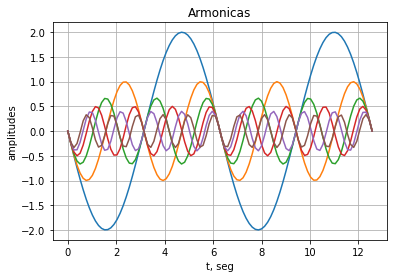

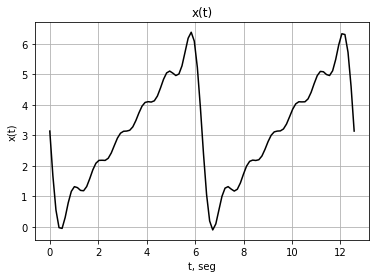

In [11]:
# Graficas
#Puede que necesite digitar dos veces shift-intro

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

fig, g = plt.subplots() 
T0n = 2*np.pi             #hay que redefinir el periodo para numpy
w0n = 2*np.pi/T0n
tm = np.linspace(0, 2*T0n, 100)

for k in range(m-1):
    g.plot(tm, ai[k]*np.cos(w0n*(k +1)*tm) + bi[k]*np.sin(w0n*(k + 1)*tm))
plt.xlabel('t, seg')
plt.ylabel('amplitudes')
plt.title('Armonicas')
plt.grid(True)
plt.show()

s = [0]*100
for k in range(m-1):
    tm = np.linspace(0, 2*T0n, 100)
    sp = (ai[k]*np.cos(w0n*(k + 1)*tm) + bi[k]*np.sin(w0n*(k + 1)*tm))
    s += sp
s = s + np.pi
plt.plot(tm, s, 'k')
plt.title('x(t)')
plt.xlabel('t, seg')
plt.ylabel('x(t)')
plt.grid(True)
plt.show()

In [18]:
import sympy as sym
from sympy import*

In [19]:
t = symbols("t")
n = symbols("n", int=True, positive=True)
T0 = 2                                         #  ingrese período período
m = 7                                             # ingreses número de componente

                                                  # construya la función por partes
ft = sym.Piecewise((0, t <=0), (t, t <=T0/2), (1, t <= T0), (0, True))
#ft = sym.Piecewise((0, t <=0), (t, t < T0/2), (1,True))
#frecuencia angular
w0 = 2*pi/T0  

In [20]:
a0 = (1/T0*integrate(ft, (t, 0, T0)))
a0

0.750000000000000

In [21]:
an = (2/T0)*integrate(ft*cos(w0*n*t), (t, 0, T0))
simplify(an)

1.0*(pi*n*sin(2*pi*n) + cos(pi*n) - 1)/(pi**2*n**2)

In [22]:
bn = (2/T0)*integrate(ft*sin(w0*n*t), (t, 0, T0))
simplify(bn)

1.0*(-pi*n*cos(2*pi*n) + sin(pi*n))/(pi**2*n**2)

In [23]:
ai = [an.subs(n, k) for k in range(1, m)]
bi = [bn.subs(n, k) for k in range(1, m)]
print('n       an       bn')
print('%d %8s       --'%(0, N(a0, 3)))
for i in range(m-1):
    print ('%d %8s %8s' %(i+1, N(ai[i], 3), N(bi[i], 3)))

n       an       bn
0    0.750       --
1   -0.203   -0.318
2        0   -0.159
3  -0.0225   -0.106
4        0  -0.0796
5 -0.00811  -0.0637
6        0  -0.0531


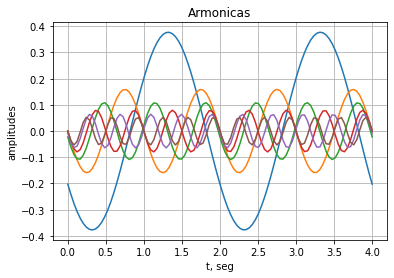

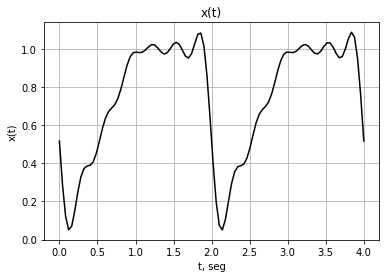

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

fig, g = plt.subplots() 
T0n = 2 #*np.pi             #hay que redefinir el periodo para numpy
w0n = 2*np.pi/T0n
tm = np.linspace(0, 2*T0n, 100)

for k in range(m-1):
    g.plot(tm, ai[k]*np.cos(w0n*(k +1)*tm) + bi[k]*np.sin(w0n*(k + 1)*tm))
plt.xlabel('t, seg')
plt.ylabel('amplitudes')
plt.title('Armonicas')
plt.grid(True)
plt.show()

s = [0]*100
for k in range(m-1):
    tm = np.linspace(0, 2*T0n, 100)
    sp = (ai[k]*np.cos(w0n*(k + 1)*tm) + bi[k]*np.sin(w0n*(k + 1)*tm))
    s += sp
s = s + 3/4
plt.plot(tm, s, 'k')
plt.title('x(t)')
plt.xlabel('t, seg')
plt.ylabel('x(t)')
plt.grid(True)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

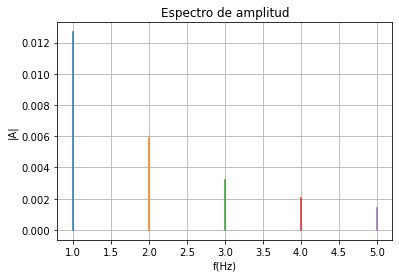

In [25]:
for i in range(m-2):
    x = [[i+1, i+1]]
    y = [[0, 0.5*abs((ai[i+1])**2 + (bi[i+1])**2)]]
    plt.plot(x[0], y[0])
#x0 = [[0, 0]]
#y0 = [[0, 3/4]]
#plt.plot(x0[0], y0[0])
plt.title('Espectro de amplitud')
plt.xlabel('f(Hz)')
plt.ylabel('|A|')
plt.grid(True)
#plt.xlim(0,5)
#plt.ylim(0,5)
plt.show